# Zilionis et al. 2019 — Non-Small Cell Lung Cancer (inDrop)
## Step 01 · Preprocessing → Gate 1 (mixing + continuity)

Load malignant cells, threshold under-populated samples, select over-dispersed genes, PCA,
Harmony-integrate on `sample`, and judge **Gate 1** on the *regenerated embedding* across an
integration-strength (theta) sweep with a per-neighbourhood metric (iLISI) and connected-component
count — never a single scalar. Cohort note: 7 patients, mixed histology (p1 = LUSC, p3–p7 = LUAD).

In [ ]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce
import scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
# custom 3CA dataloader + paths (notebook lives two levels below Puram: <Category>/<Dataset>/)
pth_3ca = os.path.abspath(os.path.join(os.getcwd(), '..', '..', '..'))  # -> .../CCCA (holds scripts/)
sys.path.append(pth_3ca)
from scripts.load import load_CCCA_adata
name = os.path.split(os.getcwd())[1]                      # Zilionis2019_Lung-3
joinkey = 'Data_Zilionis2019_Lung'
pth = os.path.join('..', '..', '..', '..')  # notebook is 6 levels below EMToolbox root
pth_data = os.path.join(pth, 'data')
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', joinkey)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', 'Lung', name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', 'Lung', name)
os.makedirs(pth_out, exist_ok=True); os.makedirs(os.path.join(pth_fig,'colorbars'), exist_ok=True)

In [ ]:
# load dataset -> select malignant cells (leaf matrix dir; Exp_data_UMIcounts.mtx -> normalize_total + log1p)
adata = load_CCCA_adata(pth_in)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
# annotate histology from Samples.csv (mixed cohort: LUSC vs LUAD)
samp = pd.read_csv(os.path.join(pth_in, 'Samples.csv'))
adata.obs['histology'] = adata.obs['sample'].map(dict(zip(samp['sample'], samp.cancer_type))).astype('category')
adata

Loading ../../../../../../data/unzip/CCCA/Data_Zilionis2019_Lung
Done.


In [ ]:
# per-sample malignant counts
n = adata.obs['sample'].value_counts().sort_values(ascending=False); n

**Min-cell threshold — derived by dominant multiplicative cliff (gap-finding), not the anchor's `>=100`.**
Sort per-sample counts descending, take successive ratios; a cut is justified only if the largest ratio
is a *dominant* cliff (ratio-of-ratios `>=1.5` over the runner-up) and the small side is below `2x` the
`100` safety floor. Otherwise fall back to the `>=100` floor.

In [ ]:
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gi = int(np.argmax(ratios)); top_r = ratios[gi]
runner = np.sort(ratios)[::-1][1]; ror = top_r / runner
lo, hi, floor = vals[gi+1], vals[gi], 100
if ror >= 1.5 and lo < 2*floor:
    thr = float(np.sqrt(lo*hi)); rule = f'dominant cliff {int(hi)}->{int(lo)} (ratio {top_r:.2f}, {ror:.2f}x runner-up, small side {int(lo)}<{2*floor}) -> geom-mean {thr:.0f}'
else:
    thr = float(floor); rule = f'degenerate gap (ratio-of-ratios {ror:.2f}) -> >=100 floor'
print('descending ratios:', np.round(ratios,2))
print('THRESHOLD =', round(thr,1), '|', rule)
keep = n.index[n >= thr]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print('kept', sorted(keep.tolist()), '->', adata.n_obs, 'cells')
print('histology of kept:', adata.obs.groupby('sample',observed=True).histology.first().to_dict())

descending ratios: [1.35 1.01 1.25 1.61 1.69 3.09]
THRESHOLD = 131.9 | dominant cliff 232->75 (ratio 3.09, 1.84x runner-up, small side 75<200) -> geom-mean 132
kept ['p1', 'p3', 'p4', 'p5', 'p6', 'p7'] -> 3920 cells
histology of kept: {'p1': 'Lung Squamous Cell Carcinoma', 'p3': 'Lung Adenocarcinoma', 'p4': 'Lung Adenocarcinoma', 'p5': 'Lung Adenocarcinoma', 'p6': 'Lung Adenocarcinoma', 'p7': 'Lung Adenocarcinoma'}


In [ ]:
# filter genes + select over-dispersed features (scFates GAM)
sc.pp.filter_genes(adata, min_cells = 3)
scf.pp.find_overdispersed(adata)
print('over-dispersed genes:', int(adata.var.highly_variable.sum()))
adata.raw = adata

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 248 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

over-dispersed genes: 248


In [ ]:
# PCA (n_pcs chosen from cumulative variance: ~50% by 20 PCs, atlas-standard scale)
sc.pp.pca(adata, n_comps = 50, use_highly_variable = True)
vr = adata.uns['pca']['variance_ratio']
print('PCA var ratio top5:', np.round(vr[:5],4), '| cum @20 =', round(vr[:20].sum(),3))
NPCS = 20

PCA var ratio top5: [0.1445 0.0917 0.0437 0.0374 0.0325] | cum @20 = 0.502


**Gate 1 — integration-strength sweep, read on the embedding.** For theta in {0,2,5,10}: same-sample
kNN fraction (lower = better mixing; random floor shown), iLISI (higher = better; ceiling = #samples),
and connected components of the kNN graph (islands). Choose the theta where mixing saturates and the
manifold is one component.

In [ ]:
s = adata.obs['sample'].values
p = pd.Series(s).value_counts(normalize=True).values
def _ss(rep,k=30):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep,return_distance=False)[:,1:]
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
def _ilisi(rep,k=30):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep,return_distance=False)[:,1:]
    c = pd.Categorical(s).codes
    return float(np.mean([1.0/np.sum((np.bincount(c[idx[i]],minlength=c.max()+1)/k)**2) for i in range(len(s))]))
print('random-mixing floor same-sample = %.3f | iLISI ceiling = %d samples' % (np.sum(p**2), len(set(s))))
print('pre-Harmony (X_pca): same-sample %.3f  iLISI %.2f' % (_ss(adata.obsm['X_pca'][:,:NPCS]), _ilisi(adata.obsm['X_pca'][:,:NPCS])))
for th in [0,2,5,10]:
    sce.pp.harmony_integrate(adata,'sample',theta=th,max_iter_harmony=30,random_state=SEED)
    rep = adata.obsm['X_pca_harmony'][:,:NPCS]
    sc.pp.neighbors(adata,n_pcs=NPCS,use_rep='X_pca_harmony',n_neighbors=30,random_state=SEED)
    ncomp,_ = connected_components(adata.obsp['connectivities'],directed=False)
    print(f'theta={th:>2}: same-sample={_ss(rep):.3f}  iLISI={_ilisi(rep):.2f}  kNN_components={ncomp}')

random-mixing floor same-sample = 0.197 | iLISI ceiling = 6 samples
pre-Harmony (X_pca): same-sample 0.907  iLISI 1.28
theta= 0: same-sample=0.810  iLISI=1.57  kNN_components=1
theta= 2: same-sample=0.636  iLISI=2.08  kNN_components=1
theta= 5: same-sample=0.413  iLISI=2.81  kNN_components=1
theta=10: same-sample=0.397  iLISI=2.95  kNN_components=1


Mixing improves monotonically and **plateaus by theta=10** (same-sample 0.81->0.40, iLISI 1.6->3.0 of 6);
the kNN graph is **one connected component at every theta** (no detached islands). Select **theta=10**
(the plateau; matches the atlas 10x integration precedent).

overall cycling fraction: 0.064


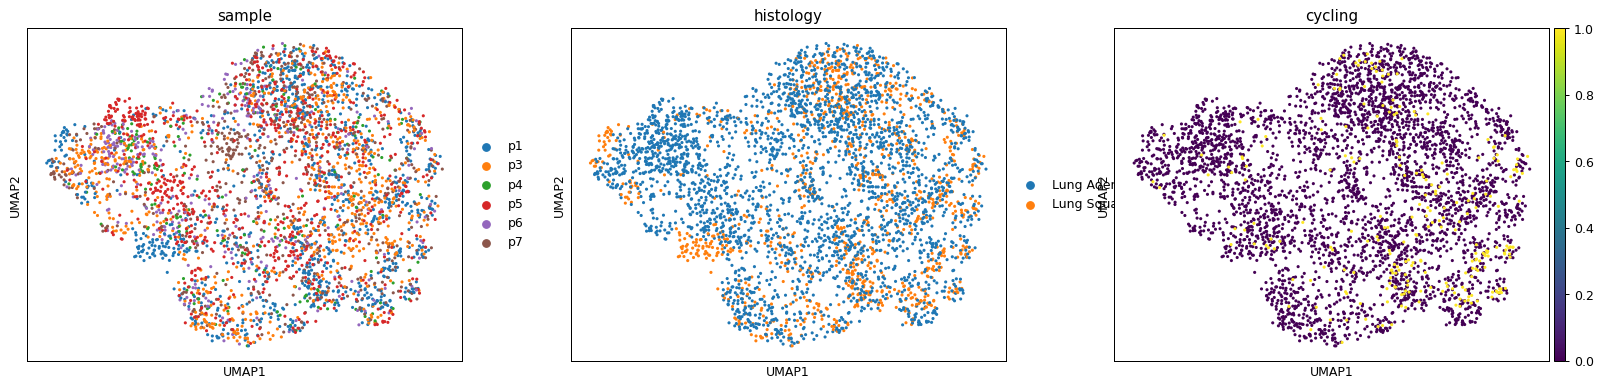

In [ ]:
# final embedding at theta=10
sce.pp.harmony_integrate(adata,'sample',theta=10,max_iter_harmony=30,random_state=SEED)
sc.pp.neighbors(adata,n_pcs=NPCS,use_rep='X_pca_harmony',n_neighbors=30,random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
# cell-cycle: publication phase (biology-before-geometry input for later scoping check)
adata.obs['cycling'] = (~adata.obs['cell_cycle_phase'].astype(str).isin(['Not cycling','nan','NaN',''])).astype(int)
print('overall cycling fraction: %.3f' % adata.obs.cycling.mean())
sc.pl.umap(adata, color=['sample','histology','cycling'], size=25, ncols=3)

The regenerated embedding is a **single continuous, roundish manifold** (all 6 samples intermix;
LUSC p1 and LUAD p3–p7 interspersed, not separate lobes; cycling low and scattered — no proliferative
compartment). Quantify continuity (one component, density has no empty waist) and mixing (per-bin sample
coverage; LUSC kNN-enrichment far below an island).

In [ ]:
from scipy.sparse.csgraph import connected_components as _cc
U = adata.obsm['X_umap']; Uc = U - U.mean(0)
cov = np.cov(Uc.T); ev = np.sort(np.linalg.eigvalsh(cov))[::-1]
print('UMAP elongation (roundish ~1):', round((ev[0]/ev[1])**0.5,2))
nc,_ = _cc(adata.obsp['connectivities'],directed=False); print('kNN components:', nc)
proj = Uc @ np.linalg.eigh(cov)[1][:,-1]
h,_ = np.histogram(proj,bins=25); print('density peak/valley along main axis:', round(h.max()/max(h.min(),1),1), '(no empty waist)')
rep = adata.obsm['X_pca_harmony'][:,:NPCS]
idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep,return_distance=False)[:,1:]
m = s=='p1'; print('LUSC(p1) kNN self-enrichment: %.1fx base (island bar ~16x)' % ((np.mean([(s[idx[i]]=="p1").mean() for i in np.where(m)[0]]))/m.mean()))

UMAP elongation (roundish ~1): 1.1
kNN components: 1
density peak/valley along main axis: 7.0 (no empty waist)
LUSC(p1) kNN self-enrichment: 2.3x base (island bar ~16x)


### Gate 1 = **GO** (mixed + continuous)
One connected component (0 detached islands), roundish (aspect ~1.1), no empty density waist; iLISI ~3.0/6
with every region carrying all samples and both histologies (LUSC enrichment only ~2x, far below an island).
Mixed **and** continuous → proceed to the manifold.

In [ ]:
# annotate: whole malignant compartment (no discrete developmental subtypes; non-branching case
# confirmed downstream). celltype carries the loader's 'Malignant' label; keep for provenance.
adata.obs['celltype'] = pd.Categorical(['Malignant']*adata.n_obs)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (3920, 28282)


saved samples.pdf


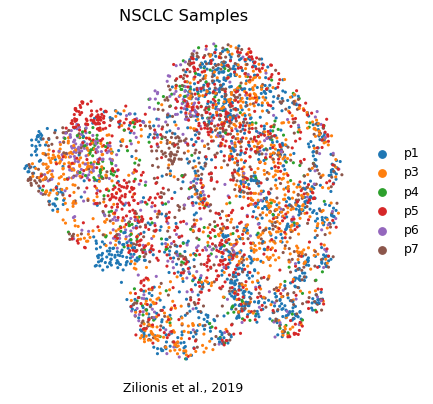

In [ ]:
# save Gate-1 sample-integration figure (reference style: single sample-colored manifold UMAP + citation)
fig, ax = plt.subplots(1, 1, figsize=(5,5))
sc.pl.umap(adata, color='sample', size=25, frameon=False, show=False, ax=ax)
ax.set_title('NSCLC Samples', size=13)
ax.text(.5, -.05, 'Zilionis et al., 2019', ha='center', transform=ax.transAxes)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf')